In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import numpy as np
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

TRIVIA_QA_PATH = os.getenv('TRIVIA_QA_PATH')
Natural_Questions_PATH = os.getenv('Natural_Questions_PATH')
SQUAD_PATH = os.getenv('SQUAD_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [3]:
from knowledge_maze.create_dataset.load_datasets import load_data
load_data(f"{REPO_PATH}\data_files\extracted_data.json")

Processing SQuAD: 100%|████████████████████████████████████████████████████████████| 442/442 [00:00<00:00, 1002.85it/s]


Loaded 272007 question-answer pairs in total.


In [2]:
# Load from saved dataset:
extracted_data = load_json(f"{REPO_PATH}\data_files\extracted_data.json")

# 2. Data preprocess:
- Filter out problematic questions (long answers, answers within questions, complex questions)
- Classify answers by types of entities
- Update entity types in the dataset

Filtering WH questions: 100%|██████████████████████████████████████████████| 272007/272007 [00:00<00:00, 402739.36it/s]


244638 out of 272007 samples have passed (89.9%).


Filtering self containing questions: 100%|█████████████████████████████████| 244638/244638 [00:02<00:00, 103866.64it/s]


242584 out of 244638 samples have passed (99.2%).


Filtering out long questions: 100%|███████████████████████████████████████| 242584/242584 [00:00<00:00, 1746131.87it/s]


...

9038 numerical samples found (4.0%).


Extracting date & time samples: 100%|██████████████████████████████████████| 226408/226408 [00:00<00:00, 537909.90it/s]


22159 date & time samples found (9.8%).


Extracting rest of the relevant samples: 100%|████████████████████████████| 226408/226408 [00:00<00:00, 3219511.80it/s]


105584 relevant samples found (46.6%).
Generating pie chart...


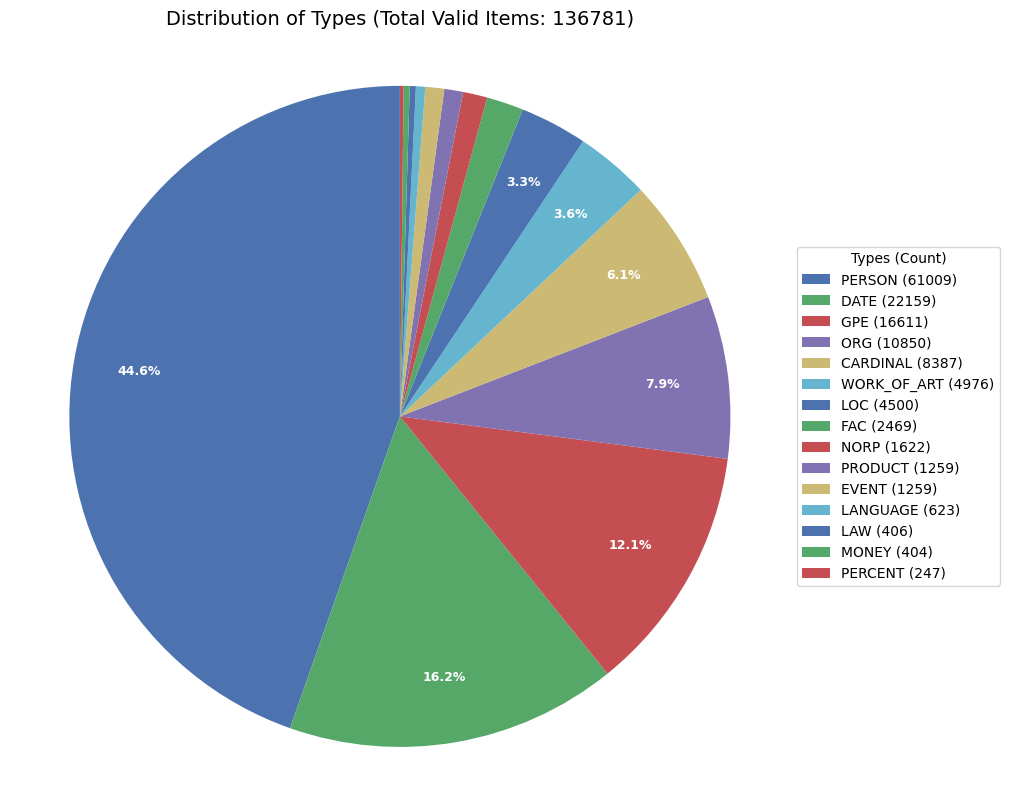

In [3]:
from knowledge_maze.create_dataset.preprocess import preprocess
processed_data = preprocess(extracted_data, output_path=f"{REPO_PATH}\data_files\processed_data.json")

In [3]:
# Load from saved dataset:
processed_data = load_json(f"{REPO_PATH}\data_files\processed_data.json")

# 3. Group questions:
- Group Questions togather based on shared answers
- Questions with numerical and date answers are grouped by closed value answers instead of exact match
- Filter out questions that are too semantically similar
- Filter out ambiguous questions
- Create candidate reasoning chains for the dataset

Dividing data by type...
Clustering data...
Creating reasoning paths for general clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 29/29 [01:18<00:00,  2.72s/it]
Creating similarity graphs and filtering questions: 100%|████████████████████████| 8359/8359 [00:06<00:00, 1330.78it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 8359/8359 [00:00<00:00, 683754.33it/s]


Creating reasoning paths for numerical clusters...


Generating question embeddings: 100%|████████████████████████████████████████████████████| 5/5 [00:13<00:00,  2.74s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████████████| 38/38 [00:06<00:00,  5.90it/s]
Splitting large clusters: 100%|███████████████████████████████████████████████████████| 38/38 [00:00<00:00, 102.07it/s]


Creating reasoning paths for date clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 11/11 [00:25<00:00,  2.33s/it]
Creating similarity graphs and filtering questions: 100%|█████████████████████████| 1106/1106 [00:06<00:00, 176.89it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 1106/1106 [00:00<00:00, 208031.76it/s]


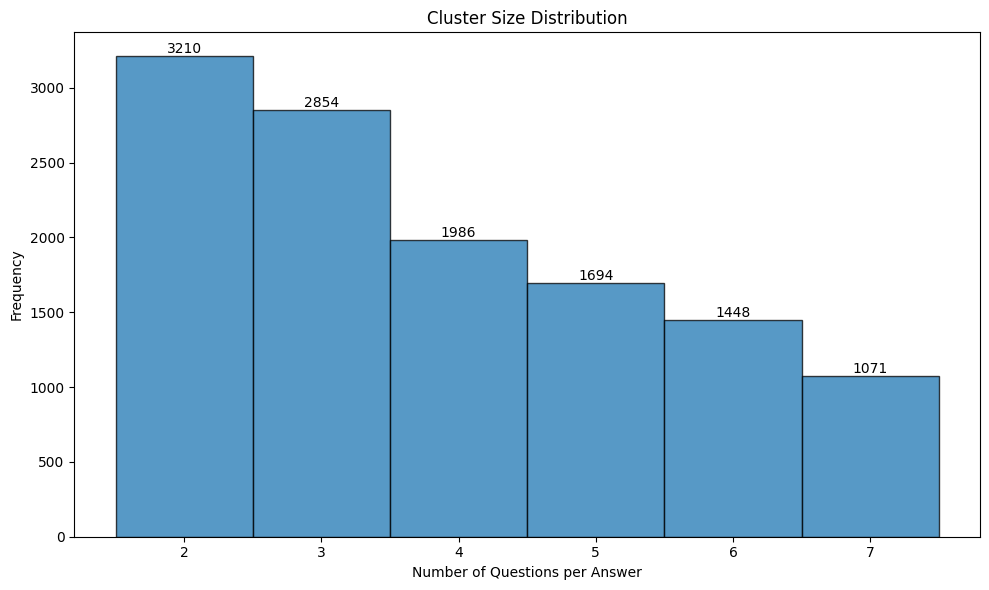

In [173]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
cluster_data = await create_paths(processed_data, output_path=f"{REPO_PATH}\data_files\cluster_data.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.02s/it]

Answer: ('Moby-Dick', 'WORK_OF_ART')
Questions before filtering:
1. Which famous book by Herman Melville opens with the line Call Me Ishmael?
2. Which 1851 novel has the alternative title ‘The Whale’?
3. Which classic novel begins, “Call me Ishmael”?


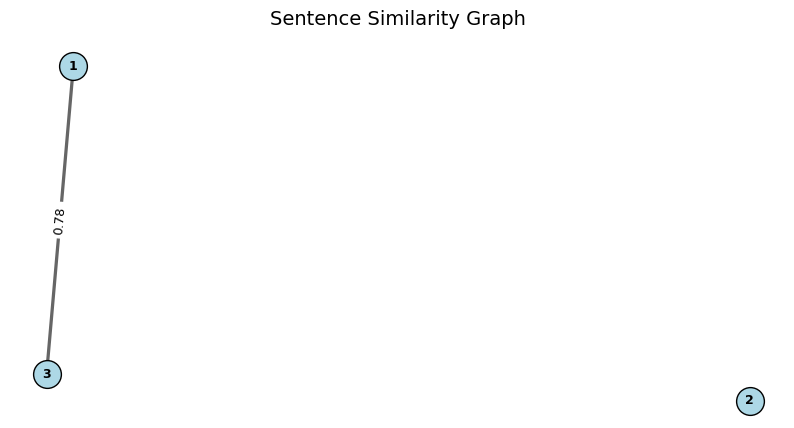

Questions after filtering:
1. Which 1851 novel has the alternative title ‘The Whale’?
2. Which classic novel begins, “Call me Ishmael”?


In [35]:
# Plot graph example - (filtering process):
from knowledge_maze.create_dataset.clustering_tools.similarity_graphs import display_random_sample
display_random_sample(processed_data)

In [4]:
# Load from saved dataset:
cluster_data = load_json(f"{REPO_PATH}\data_files\cluster_data.json")

# 4. Create Structured Data:
- ..
- ..
- ..

### TODOS:
- adjust plot similarity graph
- refactor create_data to be create_data_QA to crate the QA part of the dataset
- change the reasoning path seperation to be for 2 paths with at most 5 questions - need to see how to lose little questions as possible
- make new annotation before continue
- refactor generate_paragraphs to be create_data_paragraphs to crate the paragraphs part of the dataset
- in paragraph creation need to think of a way to make it case sensitive, or make a prompt with reasoning process...

In [5]:
cluster_data[0]

{'Answer': ['World War I', 'EVENT'],
 'Questions': ['The Battle of Caporetto was fought during which war?',
  'The Schlieffen Plan was enacted during which conflict?',
  'During which war was the Battle of Marne?',
  'On 28 June 1914, Gavrilo Princip, a Bosnian-Serb student and member of Young Bosnia, assassinated Archduke Franz Ferdinand of Austria in Sarajevo, Bosnia, which led to the start of which war?',
  'In which war did the British army first deploy tanks?',
  'During which war were occupying Ottoman forces forced to withdraw from the town of Aqaba after a raid led by T. E. Lawrence and the Arab forces of Sharif Hussein?',
  'What ended at 11am on November 11, 1918?']}

In [171]:
from knowledge_maze.create_dataset.create_data import process_data_to_list
sample = await process_data_to_list(cluster_data[:50], 'Wikipedia Entity')

Usage cost: 0.0021$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:06<00:00,  8.15it/s]


In [168]:
# Save Dataset:
output_path = f"{REPO_PATH}\data_files\\knowledge_maze_qa.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(sample, out_file)

In [172]:
sample[0]

{'ID': '04858068-8d51-4651-82c1-de0c201c11c2',
 'Question': 'The Schlieffen Plan was enacted during which conflict?',
 'Answer': {'Memory answer': 'World War I',
  'Counter answer 1': 'World War II',
  'Counter answer 2': 'The Cold War',
  'Distractor answer': 'The Vietnam War'},
 'Answer type': 'Wikipedia Entity',
 'Reasoning path 1': [{'Previous question': 'The Schlieffen Plan was enacted during which conflict?',
   'Next question': 'The Battle of Caporetto was fought during which war?',
   'Paragraph': '962ad9af-d82b-4eb8-ba48-c50d6dccf8ec'},
  {'Previous question': 'The Battle of Caporetto was fought during which war?',
   'Next question': 'During which war was the Battle of Marne?',
   'Paragraph': '7ae6aca5-9e4d-4d75-90a4-30c36a1da405'},
  {'Previous question': 'During which war was the Battle of Marne?',
   'Next question': None,
   'Paragraph': '5e23faf9-daed-4c54-b12b-9a23846bb811'}],
 'Reasoning path 2': [{'Previous question': 'The Schlieffen Plan was enacted during which con

# 5. Generate paragraphs: